In [ ]:
"""
Fully non-autoregressive (NAT) model trained with XE / AXE / OAXE / sorted-target / swap-unmatched
losses on the synthetic ordering task from the OAXE paper (Sec. 3).

Task: source = N distinct numbers. Target = the same numbers in one of k ordering modes
(direct, reverse, flip, flip-right-rev, flip-left-rev), sampled per example. At test time ANY of the
k orderings counts as a correct translation (paper's "exact match").
"""
import argparse, json, os, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from scipy.optimize import linear_sum_assignment

torch.set_num_threads(int(os.environ.get("NT", 2)))
V, N = 50, 8            # vocab size (numbers), sequence length
H = N // 2
BLANK = V               # blank token (used by AXE only; present in every softmax for simplicity)
AXE_EXTRA = 4           # AXE needs decoder length > target length so blanks can absorb the slack
SKIP_PEN = 3.0          # extra cost for skipping a target token in the AXE DP (without it the model learns to drop tokens)


def apply_mode(x, m):
    a, b = x[:, :H], x[:, H:]
    if m == 0: return x
    if m == 1: return x.flip(1)
    if m == 2: return torch.cat([b, a], 1)
    if m == 3: return torch.cat([b, a.flip(1)], 1)
    if m == 4: return torch.cat([b.flip(1), a], 1)


def sample_batch(bs, k, gen):
    src = torch.rand(bs, V, generator=gen).argsort(1)[:, :N]          # distinct numbers
    allm = torch.stack([apply_mode(src, m) for m in range(k)], 1)      # (B,k,N)
    mid = torch.randint(0, k, (bs,), generator=gen)
    tgt = allm[torch.arange(bs), mid]
    return src, tgt


class NAT(nn.Module):
    def __init__(self, out_len, d=128, h=4, ff=256, L=2):
        super().__init__()
        self.out_len = out_len
        self.emb = nn.Embedding(V + 1, d)
        self.pe = nn.Embedding(N, d)
        self.qe = nn.Embedding(out_len, d)
        self.enc = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d, h, ff, 0.0, batch_first=True, norm_first=True), L,
            enable_nested_tensor=False)
        self.dec = nn.TransformerDecoder(
            nn.TransformerDecoderLayer(d, h, ff, 0.0, batch_first=True, norm_first=True), L)
        self.out = nn.Linear(d, V + 1)

    def forward(self, src):
        mem = self.enc(self.emb(src) + self.pe(torch.arange(N)))
        q = self.qe(torch.arange(self.out_len)).unsqueeze(0).expand(src.size(0), -1, -1)
        return F.log_softmax(self.out(self.dec(q, mem)), -1)           # (B, out_len, V+1)


# ----------------------------------------------------------------------------- losses
def tok_logp(lp, y):
    """lp (B,P,V+1), y (B,N) -> cost-source matrix S[b,pos,i] = log P_pos(y_i)"""
    return lp.gather(2, y.unsqueeze(1).expand(-1, lp.size(1), -1))


def xe_from_target(lp, y):
    return -lp.gather(2, y.unsqueeze(2)).squeeze(2).sum() / y.numel()


def loss_xe(lp, y):
    return xe_from_target(lp, y)


def loss_sorted(lp, y, desc=False):
    ys = y.sort(1, descending=desc).values
    return xe_from_target(lp, ys)


def loss_oaxe(lp, y):
    """Hungarian matching between positions and target tokens, then XE on the reordered target."""
    c = -tok_logp(lp.detach(), y).cpu().numpy()                        # cost[b,pos,i]
    yn = y.cpu().numpy(); ny = yn.copy()
    for b in range(y.size(0)):
        r, cc = linear_sum_assignment(c[b])
        ny[b, r] = yn[b, cc]
    return xe_from_target(lp, torch.from_numpy(ny))


def loss_swap(lp, y):
    """Keep tokens whose argmax already matches their own slot; Hungarian only over the unmatched ones."""
    c = -tok_logp(lp.detach(), y).cpu().numpy()
    yn = y.cpu().numpy(); ny = yn.copy()
    matched = (lp.detach().argmax(2) == y).cpu().numpy()
    for b in range(y.size(0)):
        U = np.where(~matched[b])[0]
        if len(U) > 1:
            r, cc = linear_sum_assignment(c[b][np.ix_(U, U)])
            ny[b, U[r]] = yn[b, U[cc]]
    return xe_from_target(lp, torch.from_numpy(ny))


def loss_axe(lp, y):
    """Aligned cross entropy: monotonic alignment of N targets to P predictions found by DP on detached
    log-probs; loss = CE of aligned pairs + CE-to-blank of skipped predictions + skipped-target cost."""
    B, P = y.size(0), lp.size(1)
    l = lp.detach()
    ct = -tok_logp(l, y).permute(0, 2, 1)                              # (B,N_tgt,P) cost target i at pred j
    ce = -l[:, :, BLANK]                                               # (B,P) cost blank at pred j
    A = torch.zeros(B, N + 1, P + 1); ch = torch.zeros(B, N + 1, P + 1, dtype=torch.long)
    for j in range(1, P + 1):
        A[:, 0, j] = A[:, 0, j - 1] + ce[:, j - 1]; ch[:, 0, j] = 1
    for i in range(1, N + 1):
        A[:, i, 0] = A[:, i - 1, 0] + ct[:, i - 1, 0] + SKIP_PEN; ch[:, i, 0] = 2
        for j in range(1, P + 1):
            st = torch.stack([A[:, i - 1, j - 1] + ct[:, i - 1, j - 1],   # 0: align y_i -> pred j
                              A[:, i, j - 1] + ce[:, j - 1],               # 1: skip prediction j (blank)
                              A[:, i - 1, j] + ct[:, i - 1, j - 1] + SKIP_PEN], 1)  # 2: skip target i (penalised)
            A[:, i, j], ch[:, i, j] = st.min(1)
    chn, yn = ch.numpy(), y.cpu().numpy()
    bi, pi, ti = [], [], []
    for b in range(B):
        i, j = N, P
        while i > 0 or j > 0:
            c = chn[b, i, j]
            if c == 0:   pairs = (j - 1, yn[b, i - 1]); i -= 1; j -= 1
            elif c == 1: pairs = (j - 1, BLANK); j -= 1
            else:        pairs = (max(j - 1, 0), yn[b, i - 1]); i -= 1
            bi.append(b); pi.append(pairs[0]); ti.append(pairs[1])
    sel = lp[torch.tensor(bi), torch.tensor(pi), torch.tensor(ti)]
    return -sel.sum() / (B * N)


LOSSES = {'xe': loss_xe, 'oaxe': loss_oaxe, 'swap': loss_swap, 'axe': loss_axe,
          'sorted_asc': lambda lp, y: loss_sorted(lp, y, False),
          'sorted_desc': lambda lp, y: loss_sorted(lp, y, True)}


# ----------------------------------------------------------------------------- train / eval
def train(model, method, steps, lr, k, gen, bs):
    opt = torch.optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.98))
    f = LOSSES[method]
    for it in range(steps):
        for g in opt.param_groups: g['lr'] = lr * min(1.0, (it + 1) / 100)
        src, tgt = sample_batch(bs, k, gen)
        loss = f(model(src), tgt)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    return float(loss.detach())


@torch.no_grad()
def evaluate(model, k, n_eval=2000, seed=12345):
    gen = torch.Generator().manual_seed(seed)
    src = torch.rand(n_eval, V, generator=gen).argsort(1)[:, :N]
    pred = model(src).argmax(2)                                        # (E,P)
    allm = torch.stack([apply_mode(src, m) for m in range(k)], 1)
    ex = eq = rep = tot = sset = srt = 0
    for e in range(n_eval):
        seq = [t for t in pred[e].tolist() if t != BLANK]              # drop blanks (AXE); no-op otherwise
        t = torch.tensor(seq)
        if len(seq) == N:
            ex += bool((t.unsqueeze(0) == allm[e]).all(1).any())
            sset += bool((t.sort().values == src[e].sort().values).all())
            srt += bool((t == src[e].sort().values).all())
        rep += sum(seq[i] == seq[i - 1] for i in range(1, len(seq))); tot += max(len(seq) - 1, 1)
    return dict(exact_any_mode=100 * ex / n_eval, set_match=100 * sset / n_eval,
                sorted_exact=100 * srt / n_eval, repeated_tok=100 * rep / tot)


def run(k, seed, P, Fs, bs, lr, lr_ft, methods, out):
    res = {}
    t0 = time.time()
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed)
    base = NAT(N)
    train(base, 'xe', P, lr, k, gen, bs)                               # shared XE pre-training
    state = {n: v.clone() for n, v in base.state_dict().items()}
    res['xe_pretrain_only'] = evaluate(base, k)
    S = P + Fs                                                         # same total step budget for all
    for m in methods:
        torch.manual_seed(seed + 1); g = torch.Generator().manual_seed(seed + 1)
        if m in ('xe', 'oaxe', 'swap'):                                # XE-init then fine-tune with method
            model = NAT(N); model.load_state_dict(state)
            train(model, m, Fs, lr_ft, k, g, bs)
        elif m == 'axe':                                               # longer decoder, from scratch
            model = NAT(N + AXE_EXTRA); train(model, 'axe', S, lr, k, g, bs)
        elif m == 'oaxe_scratch':                                      # ablation: no XE init
            model = NAT(N); train(model, 'oaxe', S, lr, k, g, bs)
        else:                                                          # sorted_*: from scratch
            model = NAT(N); train(model, m, S, lr, k, g, bs)
        res[m] = evaluate(model, k)
        print(f'k={k} seed={seed} {m:13s} {res[m]}  [{time.time()-t0:.0f}s]', flush=True)
    json.dump(res, open(out, 'w'), indent=1)
    return res


def summarize(outdir):
    """Print mean metrics per (k, method) from the saved JSON files."""
    import glob, collections
    acc = collections.defaultdict(list)
    for f in sorted(glob.glob(f'{outdir}/k*_s*.json')):
        k = int(os.path.basename(f).split('_')[0][1:])
        for m, d in json.load(open(f)).items():
            acc[(k, m)].append(d)
    print(f"\n{'k':>2} {'method':18s} {'exact%':>7} {'set%':>7} {'repeat%':>8}  seeds")
    for (k, m), ds in sorted(acc.items()):
        mean = lambda key: sum(d[key] for d in ds) / len(ds)
        print(f"{k:>2} {m:18s} {mean('exact_any_mode'):7.1f} {mean('set_match'):7.1f} "
              f"{mean('repeated_tok'):8.1f}  {len(ds)}")


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument('--k', type=int, nargs='+', default=[1, 3, 5])
    ap.add_argument('--seeds', type=int, nargs='+', default=[0])
    ap.add_argument('--pre', type=int, default=800)
    ap.add_argument('--ft', type=int, default=800)
    ap.add_argument('--bs', type=int, default=64)
    ap.add_argument('--methods', nargs='+',
                    default=['xe', 'axe', 'oaxe', 'swap', 'sorted_asc', 'sorted_desc', 'oaxe_scratch'])
    ap.add_argument('--outdir', default='results')
    a, _ = ap.parse_known_args(argv)          # ignores Jupyter/Colab's extra "-f kernel.json" argument
    os.makedirs(a.outdir, exist_ok=True)
    for seed in a.seeds:
        for k in a.k:
            run(k, seed, a.pre, a.ft, a.bs, 1e-3, 3e-4, a.methods, f'{a.outdir}/k{k}_s{seed}.json')
    summarize(a.outdir)


if __name__ == '__main__':
    main()

k=1 seed=0 xe            {'exact_any_mode': 100.0, 'set_match': 100.0, 'sorted_exact': 0.0, 'repeated_tok': 0.0}  [152s]
k=1 seed=0 axe           {'exact_any_mode': 100.0, 'set_match': 100.0, 'sorted_exact': 0.0, 'repeated_tok': 0.0}  [353s]
k=1 seed=0 oaxe          {'exact_any_mode': 100.0, 'set_match': 100.0, 'sorted_exact': 0.0, 'repeated_tok': 0.0}  [432s]
k=1 seed=0 swap          {'exact_any_mode': 100.0, 'set_match': 100.0, 'sorted_exact': 0.0, 'repeated_tok': 0.0}  [507s]
k=1 seed=0 sorted_asc    {'exact_any_mode': 0.0, 'set_match': 85.4, 'sorted_exact': 85.4, 'repeated_tok': 2.1785714285714284}  [659s]
k=1 seed=0 sorted_desc   {'exact_any_mode': 0.0, 'set_match': 91.35, 'sorted_exact': 0.0, 'repeated_tok': 1.2214285714285715}  [806s]
k=1 seed=0 oaxe_scratch  {'exact_any_mode': 0.0, 'set_match': 75.05, 'sorted_exact': 0.0, 'repeated_tok': 0.7857142857142857}  [955s]
k=3 seed=0 xe            {'exact_any_mode': 0.45, 'set_match': 0.9, 'sorted_exact': 0.0, 'repeated_tok': 13.157142

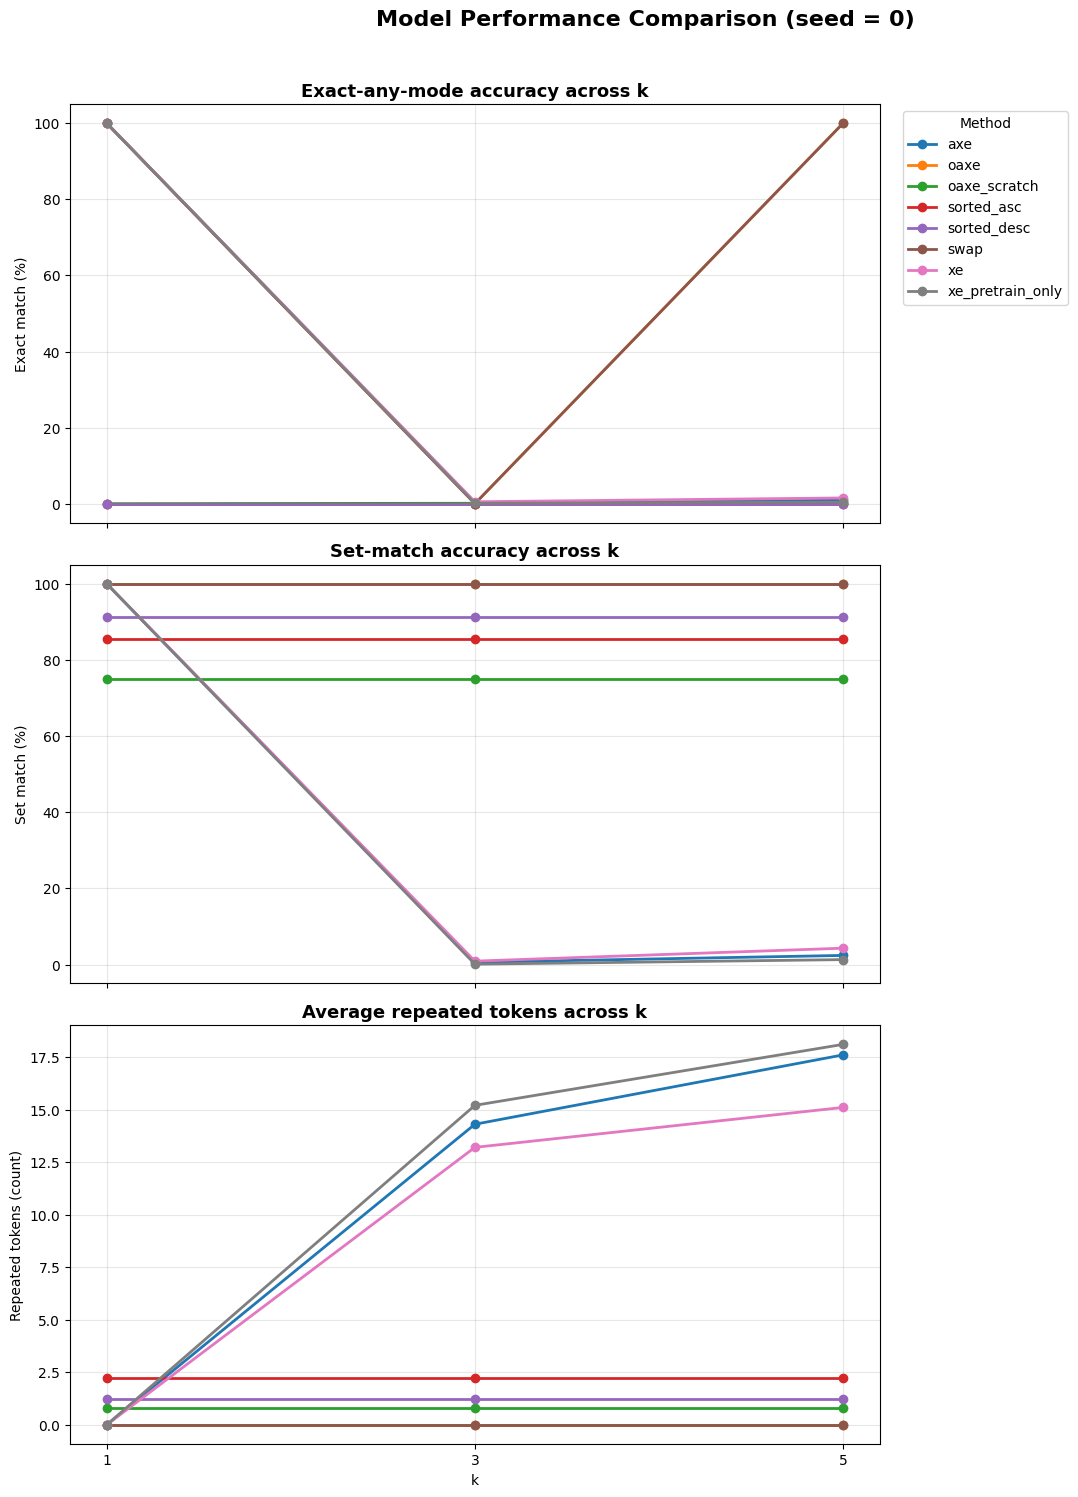

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

data = [
    (1, "axe", 100.0, 100.0, 0.0),
    (1, "oaxe", 100.0, 100.0, 0.0),
    (1, "oaxe_scratch", 0.0, 75.0, 0.8),
    (1, "sorted_asc", 0.0, 85.4, 2.2),
    (1, "sorted_desc", 0.0, 91.3, 1.2),
    (1, "swap", 100.0, 100.0, 0.0),
    (1, "xe", 100.0, 100.0, 0.0),
    (1, "xe_pretrain_only", 100.0, 100.0, 0.0),
    (3, "axe", 0.2, 0.6, 14.3),
    (3, "oaxe", 0.0, 100.0, 0.0),
    (3, "oaxe_scratch", 0.1, 75.0, 0.8),
    (3, "sorted_asc", 0.0, 85.4, 2.2),
    (3, "sorted_desc", 0.0, 91.3, 1.2),
    (3, "swap", 0.0, 100.0, 0.0),
    (3, "xe", 0.5, 0.9, 13.2),
    (3, "xe_pretrain_only", 0.1, 0.1, 15.2),
    (5, "axe", 0.9, 2.4, 17.6),
    (5, "oaxe", 100.0, 100.0, 0.0),
    (5, "oaxe_scratch", 0.1, 75.0, 0.8),
    (5, "sorted_asc", 0.0, 85.4, 2.2),
    (5, "sorted_desc", 0.0, 91.3, 1.2),
    (5, "swap", 100.0, 100.0, 0.0),
    (5, "xe", 1.5, 4.3, 15.1),
    (5, "xe_pretrain_only", 0.4, 1.3, 18.1),
]

df = pd.DataFrame(data, columns=[
    "k", "method", "exact_pct", "set_match_pct", "repeated_tokens"
])
methods = ["axe", "oaxe", "oaxe_scratch", "sorted_asc",
           "sorted_desc", "swap", "xe", "xe_pretrain_only"]

fig, axes = plt.subplots(3, 1, figsize=(13, 15), sharex=True)
metrics = [
    ("exact_pct", "Exact match (%)", "Exact-any-mode accuracy across k"),
    ("set_match_pct", "Set match (%)", "Set-match accuracy across k"),
    ("repeated_tokens", "Repeated tokens (count)", "Average repeated tokens across k"),
]

for ax, (column, ylabel, title) in zip(axes, metrics):
    for method in methods:
        subset = df[df["method"] == method].sort_values("k")
        ax.plot(subset["k"], subset[column], marker="o",
                linewidth=2, markersize=6, label=method)
    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks([1, 3, 5])
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("k")
axes[0].legend(title="Method", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Model Performance Comparison (seed = 0)",
             fontsize=16, weight="bold", y=0.995)
fig.tight_layout(rect=[0, 0, 0.84, 0.98])
plt.savefig("model_performance_visualization.png", dpi=220, bbox_inches="tight")
plt.show()


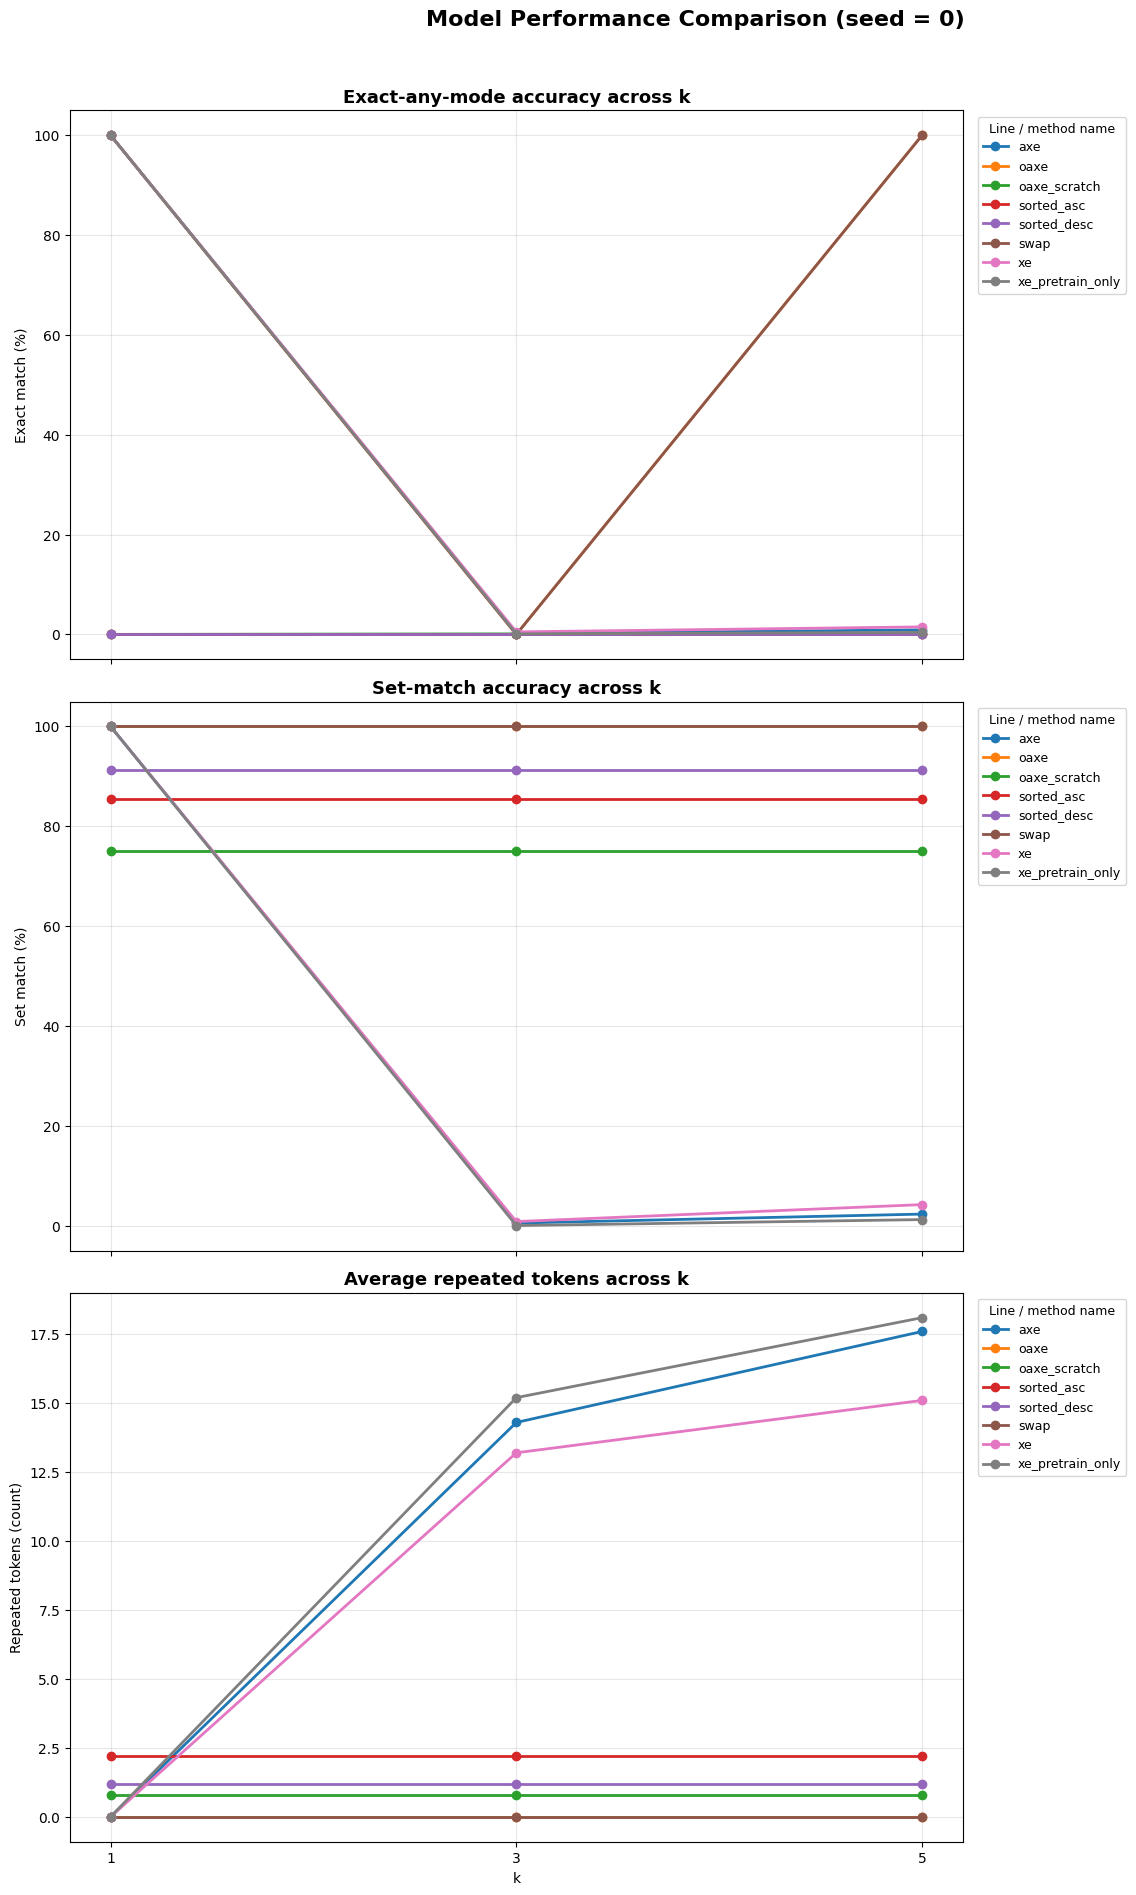

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

data = [
    (1, "axe", 100.0, 100.0, 0.0),
    (1, "oaxe", 100.0, 100.0, 0.0),
    (1, "oaxe_scratch", 0.0, 75.0, 0.8),
    (1, "sorted_asc", 0.0, 85.4, 2.2),
    (1, "sorted_desc", 0.0, 91.3, 1.2),
    (1, "swap", 100.0, 100.0, 0.0),
    (1, "xe", 100.0, 100.0, 0.0),
    (1, "xe_pretrain_only", 100.0, 100.0, 0.0),
    (3, "axe", 0.2, 0.6, 14.3),
    (3, "oaxe", 0.0, 100.0, 0.0),
    (3, "oaxe_scratch", 0.1, 75.0, 0.8),
    (3, "sorted_asc", 0.0, 85.4, 2.2),
    (3, "sorted_desc", 0.0, 91.3, 1.2),
    (3, "swap", 0.0, 100.0, 0.0),
    (3, "xe", 0.5, 0.9, 13.2),
    (3, "xe_pretrain_only", 0.1, 0.1, 15.2),
    (5, "axe", 0.9, 2.4, 17.6),
    (5, "oaxe", 100.0, 100.0, 0.0),
    (5, "oaxe_scratch", 0.1, 75.0, 0.8),
    (5, "sorted_asc", 0.0, 85.4, 2.2),
    (5, "sorted_desc", 0.0, 91.3, 1.2),
    (5, "swap", 100.0, 100.0, 0.0),
    (5, "xe", 1.5, 4.3, 15.1),
    (5, "xe_pretrain_only", 0.4, 1.3, 18.1),
]

df = pd.DataFrame(data, columns=[
    "k", "method", "exact_pct", "set_match_pct", "repeated_tokens"
])
methods = ["axe", "oaxe", "oaxe_scratch", "sorted_asc",
           "sorted_desc", "swap", "xe", "xe_pretrain_only"]

fig, axes = plt.subplots(3, 1, figsize=(14, 19), sharex=True)
metrics = [
    ("exact_pct", "Exact match (%)", "Exact-any-mode accuracy across k"),
    ("set_match_pct", "Set match (%)", "Set-match accuracy across k"),
    ("repeated_tokens", "Repeated tokens (count)", "Average repeated tokens across k"),
]

for ax, (column, ylabel, title) in zip(axes, metrics):
    for method in methods:
        subset = df[df["method"] == method].sort_values("k")
        ax.plot(subset["k"], subset[column], marker="o",
                linewidth=2, markersize=6, label=method)
    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks([1, 3, 5])
    ax.grid(True, alpha=0.3)
    # Legend identifies every plotted line by its method name.
    ax.legend(title="Line / method name", loc="upper left",
              bbox_to_anchor=(1.01, 1), fontsize=9, title_fontsize=9)

axes[-1].set_xlabel("k")
fig.suptitle("Model Performance Comparison (seed = 0)",
             fontsize=16, weight="bold", y=0.995)
fig.tight_layout(rect=[0, 0, 0.82, 0.98])
plt.savefig("model_performance_named_lines.png", dpi=220, bbox_inches="tight")
plt.show()


seed=0 xe                set_exact=   0.0  coverage=  33.7  duplicates= 66.3   [175s]
seed=0 axe               set_exact=   0.0  coverage=  31.2  duplicates= 68.8   [393s]
seed=0 sorted            set_exact=  96.0  coverage=  99.5  duplicates=  0.5   [555s]
seed=0 oaxe_scratch      set_exact=  81.8  coverage=  97.6  duplicates=  2.3   [722s]
seed=0 xe_then_oaxe      set_exact=  60.2  coverage=  94.5  duplicates=  5.5   [803s]
seed=0 sorted_then_oaxe  set_exact=  98.8  coverage=  99.8  duplicates=  0.1   [885s]
seed=0 sorted_then_swap  set_exact=  98.8  coverage=  99.8  duplicates=  0.1   [967s]
seed=1 xe                set_exact=   0.0  coverage=  33.5  duplicates= 66.5   [159s]
seed=1 axe               set_exact=   0.0  coverage=  31.1  duplicates= 69.0   [374s]
seed=1 sorted            set_exact=  97.9  coverage=  99.7  duplicates=  0.3   [534s]
seed=1 oaxe_scratch      set_exact=  82.2  coverage=  97.6  duplicates=  2.3   [698s]
seed=1 xe_then_oaxe      set_exact=  63.5  coverage=  

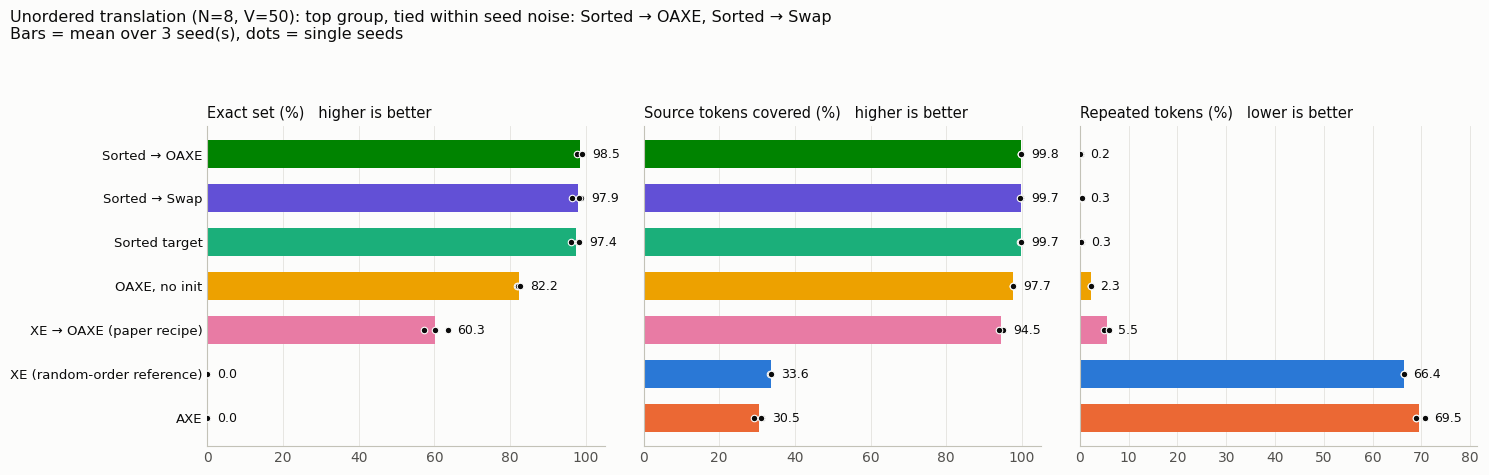

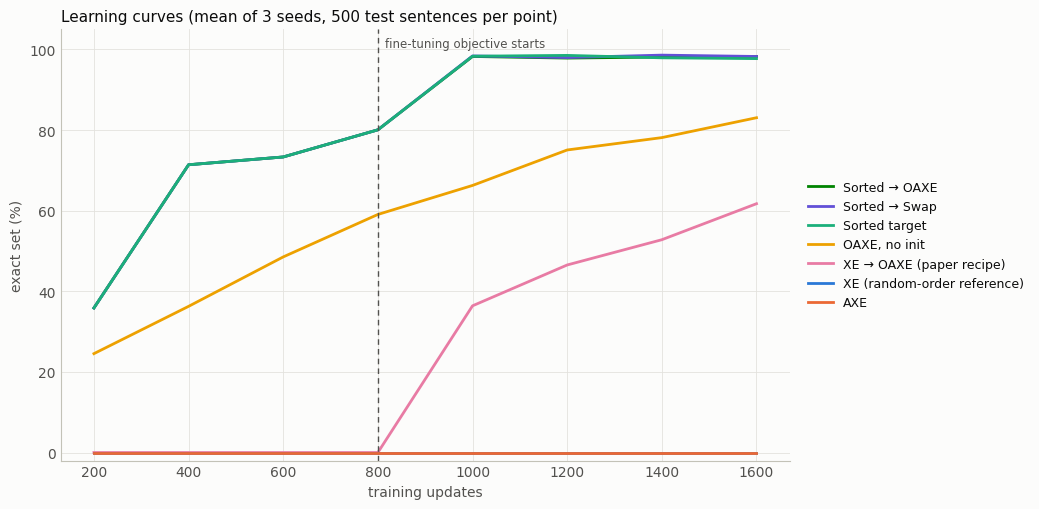

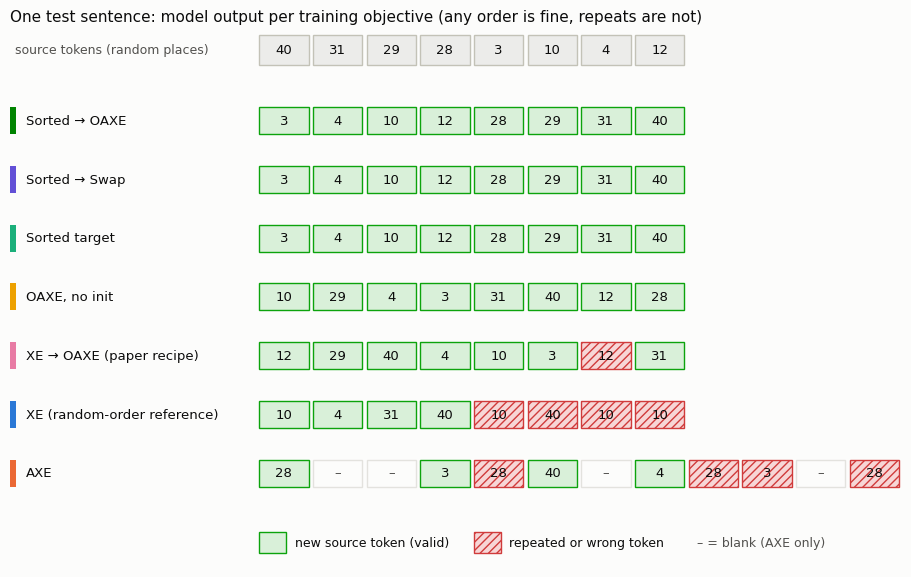

In [ ]:
"""
Unordered "translation" with a fully non-autoregressive (NAT) model.

Task
----
source = N distinct tokens at random positions.
target = the SAME tokens, but in a fresh random order for every example.
There is no "correct" order, so the only thing that can be correct is the SET of tokens.

Training objectives compared
----------------------------
xe                 plain cross entropy against the (random-order) reference
axe                aligned cross entropy (monotonic alignment + blanks)
sorted             reference is sorted ascending (canonical order)
oaxe_scratch       OAXE (Hungarian-matched reference), no initialisation
xe_then_oaxe       OAXE after XE pre-training            (the paper's recipe)
sorted_then_oaxe   OAXE after sorted-target pre-training (proposed for unordered sets)
sorted_then_swap   swap-unmatched variant after sorted pre-training

Every method gets the same total number of updates (--pre + --ft).

Metrics (computed on 2000 fresh test examples)
----------------------------------------------
set_exact   % of predictions that are exactly the source tokens (any order)
coverage    % of source tokens that appear in the prediction
duplicates  % of predicted positions that repeat a token already predicted

Run (script or Colab cell):   python unordered_nat.py --seeds 0 1 2
Plots only:                   python unordered_nat.py --plot_only
"""
import argparse, glob, json, os, sys, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from scipy.optimize import linear_sum_assignment

torch.set_num_threads(int(os.environ.get("NT", 2)))
V, N = 50, 8            # vocabulary size, number of tokens in every sentence
BLANK = V               # blank symbol (only AXE ever targets it)
AXE_EXTRA = 4           # extra decoder slots for AXE so blanks can absorb the slack
SKIP_PEN = 3.0          # AXE: extra cost for skipping a target token (stops it dropping tokens)


# ----------------------------------------------------------------------------- data
def sample_batch(bs, gen):
    src = torch.rand(bs, V, generator=gen).argsort(1)[:, :N]          # N distinct tokens, random places
    perm = torch.rand(bs, N, generator=gen).argsort(1)
    tgt = src.gather(1, perm)                                          # same tokens, fresh random order
    return src, tgt


# ----------------------------------------------------------------------------- model
class NAT(nn.Module):
    """Source encoder + decoder whose inputs are position queries only (all positions in parallel)."""
    def __init__(self, out_len, d=128, h=4, ff=256, L=2):
        super().__init__()
        self.emb = nn.Embedding(V + 1, d)
        self.pe = nn.Embedding(N, d)
        self.qe = nn.Embedding(out_len, d)
        self.enc = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d, h, ff, 0.0, batch_first=True, norm_first=True), L,
            enable_nested_tensor=False)
        self.dec = nn.TransformerDecoder(
            nn.TransformerDecoderLayer(d, h, ff, 0.0, batch_first=True, norm_first=True), L)
        self.out = nn.Linear(d, V + 1)
        self.out_len = out_len

    def forward(self, src):
        mem = self.enc(self.emb(src) + self.pe(torch.arange(N)))
        q = self.qe(torch.arange(self.out_len)).unsqueeze(0).expand(src.size(0), -1, -1)
        return F.log_softmax(self.out(self.dec(q, mem)), -1)           # (B, out_len, V+1)


# ----------------------------------------------------------------------------- losses
def tok_logp(lp, y):
    """S[b, pos, i] = log P_pos(y_i)"""
    return lp.gather(2, y.unsqueeze(1).expand(-1, lp.size(1), -1))


def xe_from_target(lp, y):
    return -lp.gather(2, y.unsqueeze(2)).squeeze(2).sum() / y.numel()


def loss_xe(lp, y):
    return xe_from_target(lp, y)


def loss_sorted(lp, y):
    return xe_from_target(lp, y.sort(1).values)


def loss_oaxe(lp, y):
    """Hungarian matching of target tokens to positions, then plain XE on the reordered reference."""
    c = -tok_logp(lp.detach(), y).cpu().numpy()
    yn = y.cpu().numpy(); ny = yn.copy()
    for b in range(y.size(0)):
        r, cc = linear_sum_assignment(c[b])
        ny[b, r] = yn[b, cc]
    return xe_from_target(lp, torch.from_numpy(ny))


def loss_swap(lp, y):
    """Keep tokens whose argmax already equals their own slot; Hungarian only over the unmatched slots."""
    c = -tok_logp(lp.detach(), y).cpu().numpy()
    yn = y.cpu().numpy(); ny = yn.copy()
    matched = (lp.detach().argmax(2) == y).cpu().numpy()
    for b in range(y.size(0)):
        U = np.where(~matched[b])[0]
        if len(U) > 1:
            r, cc = linear_sum_assignment(c[b][np.ix_(U, U)])
            ny[b, U[r]] = yn[b, U[cc]]
    return xe_from_target(lp, torch.from_numpy(ny))


def loss_axe(lp, y):
    """Aligned cross entropy: best MONOTONIC alignment (dynamic programming on detached log-probs);
    aligned pairs get CE, skipped predictions are pushed to the blank, skipped targets pay SKIP_PEN."""
    B, P = y.size(0), lp.size(1)
    l = lp.detach()
    ct = -tok_logp(l, y).permute(0, 2, 1)                              # (B, N, P) cost of y_i at pred j
    ce = -l[:, :, BLANK]                                               # (B, P)   cost of blank at pred j
    A = torch.zeros(B, N + 1, P + 1); ch = torch.zeros(B, N + 1, P + 1, dtype=torch.long)
    for j in range(1, P + 1):
        A[:, 0, j] = A[:, 0, j - 1] + ce[:, j - 1]; ch[:, 0, j] = 1
    for i in range(1, N + 1):
        A[:, i, 0] = A[:, i - 1, 0] + ct[:, i - 1, 0] + SKIP_PEN; ch[:, i, 0] = 2
        for j in range(1, P + 1):
            st = torch.stack([A[:, i - 1, j - 1] + ct[:, i - 1, j - 1],                 # align y_i -> pred j
                              A[:, i, j - 1] + ce[:, j - 1],                             # skip pred j (blank)
                              A[:, i - 1, j] + ct[:, i - 1, j - 1] + SKIP_PEN], 1)       # skip target i
            A[:, i, j], ch[:, i, j] = st.min(1)
    chn, yn = ch.numpy(), y.cpu().numpy()
    bi, pi, ti = [], [], []
    for b in range(B):
        i, j = N, P
        while i > 0 or j > 0:
            c = chn[b, i, j]
            if c == 0:   pj, tok = j - 1, yn[b, i - 1]; i -= 1; j -= 1
            elif c == 1: pj, tok = j - 1, BLANK; j -= 1
            else:        pj, tok = max(j - 1, 0), yn[b, i - 1]; i -= 1
            bi.append(b); pi.append(pj); ti.append(tok)
    sel = lp[torch.tensor(bi), torch.tensor(pi), torch.tensor(ti)]
    return -sel.sum() / (B * N)


LOSSES = {'xe': loss_xe, 'axe': loss_axe, 'sorted': loss_sorted, 'oaxe': loss_oaxe, 'swap': loss_swap}

# name -> (pre-training objective or None, main objective)
SPEC = {
    'xe':               dict(pre='xe',     loss='xe'),
    'axe':              dict(pre=None,     loss='axe'),
    'sorted':           dict(pre='sorted', loss='sorted'),
    'oaxe_scratch':     dict(pre=None,     loss='oaxe'),
    'xe_then_oaxe':     dict(pre='xe',     loss='oaxe'),
    'sorted_then_oaxe': dict(pre='sorted', loss='oaxe'),
    'sorted_then_swap': dict(pre='sorted', loss='swap'),
}
LABEL = {'xe': 'XE (random-order reference)', 'axe': 'AXE', 'sorted': 'Sorted target',
         'oaxe_scratch': 'OAXE, no init', 'xe_then_oaxe': 'XE → OAXE (paper recipe)',
         'sorted_then_oaxe': 'Sorted → OAXE', 'sorted_then_swap': 'Sorted → Swap'}


# ----------------------------------------------------------------------------- train / eval
@torch.no_grad()
def evaluate(model, n_eval=2000, seed=12345):
    gen = torch.Generator().manual_seed(seed)
    src = torch.rand(n_eval, V, generator=gen).argsort(1)[:, :N]
    pred = model(src).argmax(2).tolist()
    srcl = src.tolist()
    se = cov = dup = 0.0
    for e in range(n_eval):
        seq = [t for t in pred[e] if t != BLANK]                       # blanks are dropped (AXE only)
        se += (len(seq) == N and sorted(seq) == sorted(srcl[e]))
        cov += len(set(seq) & set(srcl[e])) / N
        dup += (len(seq) - len(set(seq))) / max(len(seq), 1)
    return dict(set_exact=100 * se / n_eval, coverage=100 * cov / n_eval, duplicates=100 * dup / n_eval)


def train(model, kind, steps, lr, gen, bs, curve=None, step0=0, eval_every=200):
    opt = torch.optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.98))
    f = LOSSES[kind]
    for it in range(steps):
        for g in opt.param_groups:
            g['lr'] = lr * min(1.0, (it + 1) / 100)                    # short warm-up
        src, tgt = sample_batch(bs, gen)
        loss = f(model(src), tgt)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if curve is not None and (it + 1) % eval_every == 0:
            curve.append([step0 + it + 1, evaluate(model, 500)['set_exact']])
    return model


def run_seed(seed, P, Fs, bs, lr, lr_ft, methods, path):
    t0 = time.time(); S = P + Fs
    ex_src = torch.rand(3, V, generator=torch.Generator().manual_seed(2024)).argsort(1)[:, :N]
    pre_cache, res = {}, {'_src_examples': ex_src.tolist()}

    def pretrained(kind):                                              # shared across methods that need it
        if kind not in pre_cache:
            torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
            m, curve = NAT(N), []
            train(m, kind, P, lr, g, bs, curve, 0)
            pre_cache[kind] = ({k: v.clone() for k, v in m.state_dict().items()}, curve)
        return pre_cache[kind]

    for name in methods:
        spec = SPEC[name]
        torch.manual_seed(seed + 1); g = torch.Generator().manual_seed(seed + 1)
        curve = []
        if spec['pre']:
            state, c0 = pretrained(spec['pre'])
            model = NAT(N); model.load_state_dict(state); curve = list(c0)
            train(model, spec['loss'], Fs, lr_ft, g, bs, curve, P)
        else:
            model = NAT(N + AXE_EXTRA if spec['loss'] == 'axe' else N)
            train(model, spec['loss'], S, lr, g, bs, curve, 0)
        r = evaluate(model); r['curve'] = curve
        with torch.no_grad():
            r['examples'] = [[-1 if t == BLANK else t for t in row] for row in model(ex_src).argmax(2).tolist()]
        res[name] = r
        print(f"seed={seed} {name:17s} set_exact={r['set_exact']:6.1f}  coverage={r['coverage']:6.1f}  "
              f"duplicates={r['duplicates']:5.1f}   [{time.time()-t0:.0f}s]", flush=True)
        json.dump(res, open(path, 'w'))
    return res


# ----------------------------------------------------------------------------- plots
SURF, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e3e2de'
# validated categorical palette, assigned in fixed order (colour follows the method, never its rank)
COLOR = {'xe': '#2a78d6', 'axe': '#eb6834', 'sorted': '#1baf7a', 'oaxe_scratch': '#eda100',
         'xe_then_oaxe': '#e87ba4', 'sorted_then_oaxe': '#008300', 'sorted_then_swap': '#6250d6'}


def _style(ax):
    ax.set_facecolor(SURF)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color('#c3c2b7')
    ax.tick_params(colors=INK2, length=0)
    ax.grid(color=GRID, linewidth=0.6); ax.set_axisbelow(True)


def plot_all(outdir, P):
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    files = sorted(glob.glob(f'{outdir}/seed*.json'))
    runs = [json.load(open(f)) for f in files]
    names = [m for m in SPEC if runs and all(m in r for r in runs)]
    mean = lambda m, k: float(np.mean([r[m][k] for r in runs]))
    order = sorted(names, key=lambda m: -mean(m, 'set_exact'))
    best = order[0]

    # ---- Figure 1: final metrics, one row per method (mean bar, one dot per seed)
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True, facecolor=SURF)
    panels = [('set_exact', 'Exact set (%)   higher is better', 105),
              ('coverage', 'Source tokens covered (%)   higher is better', 105),
              ('duplicates', 'Repeated tokens (%)   lower is better', None)]
    for ax, (key, title, xmax) in zip(axs, panels):
        _style(ax); ax.grid(axis='y', visible=False)
        top = max(max(r[m][key] for r in runs) for m in order)
        for i, m in enumerate(order):
            vals = [r[m][key] for r in runs]; mu = float(np.mean(vals))
            ax.barh(i, mu, height=0.62, color=COLOR[m], linewidth=0)
            ax.scatter(vals, [i] * len(vals), s=22, color=INK, edgecolor=SURF, linewidth=0.8, zorder=3)
            ax.text(max(vals) + (xmax or max(top, 20)) * 0.025, i, f'{mu:.1f}', va='center', fontsize=9, color=INK)
        ax.set_xlim(0, xmax or max(top * 1.15, 20))
        ax.set_title(title, loc='left', fontsize=10.5, color=INK)
        ax.set_yticks(range(len(order))); ax.set_yticklabels([LABEL[m] for m in order], fontsize=9.5, color=INK)
        ax.invert_yaxis()
    sd_best = max(float(np.std([r[best]['set_exact'] for r in runs])), 1.0)
    tied = [m for m in order if mean(m, 'set_exact') >= mean(best, 'set_exact') - sd_best]
    verdict = (f'best = {LABEL[best]} ({mean(best, "set_exact"):.1f}%)' if len(tied) == 1 else
               f'top group, tied within seed noise: ' + ', '.join(LABEL[m] for m in tied))
    fig.suptitle(f'Unordered translation (N={N}, V={V}): {verdict}\n'
                 f'Bars = mean over {len(runs)} seed(s), dots = single seeds',
                 x=0.01, ha='left', fontsize=11.5, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.91))
    fig.savefig(f'{outdir}/fig1_summary.png', dpi=150, facecolor=SURF)

    # ---- Figure 2: learning curves (mean over seeds)
    fig, ax = plt.subplots(figsize=(10.5, 5.2), facecolor=SURF); _style(ax)
    for m in order:
        c = np.mean([[p[1] for p in r[m]['curve']] for r in runs], 0)
        xs = [p[0] for p in runs[0][m]['curve']]
        ax.plot(xs, c, color=COLOR[m], linewidth=2, label=LABEL[m])
    ax.axvline(P, color=INK2, linestyle=(0, (4, 3)), linewidth=1)
    ax.text(P + 15, 103, 'fine-tuning objective starts', fontsize=8.5, color=INK2, va='top')
    ax.set_ylim(-2, 105); ax.set_xlabel('training updates', color=INK2); ax.set_ylabel('exact set (%)', color=INK2)
    ax.set_title(f'Learning curves (mean of {len(runs)} seeds, 500 test sentences per point)', loc='left',
                 fontsize=11, color=INK)
    leg = ax.legend(frameon=False, fontsize=9, loc='center left', bbox_to_anchor=(1.01, 0.5))
    for t in leg.get_texts(): t.set_color(INK)
    fig.tight_layout(); fig.savefig(f'{outdir}/fig2_curves.png', dpi=150, facecolor=SURF)

    # ---- Figure 3: what each model actually outputs for one source (seed 0)
    r0 = runs[0]; ex = 0
    src = r0['_src_examples'][ex]
    ncol = N + AXE_EXTRA
    fig, ax = plt.subplots(figsize=(11.5, 0.62 * (len(order) + 2) + 1.4), facecolor=SURF)
    ax.set_xlim(-4.6, ncol); ax.set_ylim(len(order) + 1.35, -0.8); ax.axis('off')
    ax.text(-4.5, -0.45, 'source tokens (random places)', fontsize=9, color=INK2, va='center')
    for c, t in enumerate(src):
        ax.add_patch(Rectangle((c + 0.04, -0.7), 0.92, 0.5, facecolor='#ececea', edgecolor='#c3c2b7'))
        ax.text(c + 0.5, -0.45, str(t), ha='center', va='center', fontsize=9.5, color=INK)
    for i, m in enumerate(order):
        y = i + 0.5; seen = set()
        ax.text(-4.3, y + 0.25, LABEL[m], fontsize=9.5, color=INK, va='center')
        ax.add_patch(Rectangle((-4.6, y + 0.02), 0.12, 0.46, facecolor=COLOR[m], linewidth=0))
        for c, t in enumerate(r0[m]['examples'][ex]):
            if t == -1:
                ax.add_patch(Rectangle((c + 0.04, y + 0.02), 0.92, 0.46, facecolor=SURF, edgecolor=GRID))
                ax.text(c + 0.5, y + 0.25, '–', ha='center', va='center', fontsize=9.5, color=INK2); continue
            good = (t in src) and (t not in seen); seen.add(t)
            ax.add_patch(Rectangle((c + 0.04, y + 0.02), 0.92, 0.46,
                                   facecolor='#d9f0d9' if good else '#f7d6d6',
                                   edgecolor='#0ca30c' if good else '#d03b3b', linewidth=1.0,
                                   hatch=None if good else '////'))
            ax.text(c + 0.5, y + 0.25, str(t), ha='center', va='center', fontsize=9.5, color=INK)
    yy = len(order) + 0.75
    ax.add_patch(Rectangle((0.04, yy), 0.5, 0.36, facecolor='#d9f0d9', edgecolor='#0ca30c'))
    ax.text(0.7, yy + 0.18, 'new source token (valid)', fontsize=9, color=INK, va='center')
    ax.add_patch(Rectangle((4.04, yy), 0.5, 0.36, facecolor='#f7d6d6', edgecolor='#d03b3b', hatch='////'))
    ax.text(4.7, yy + 0.18, 'repeated or wrong token', fontsize=9, color=INK, va='center')
    ax.text(8.2, yy + 0.18, '– = blank (AXE only)', fontsize=9, color=INK2, va='center')
    ax.set_title('One test sentence: model output per training objective (any order is fine, repeats are not)',
                 loc='left', fontsize=11, color=INK)
    fig.savefig(f'{outdir}/fig3_examples.png', dpi=150, facecolor=SURF, bbox_inches='tight')

    # ---- text table
    print(f"\n{'method':32s} {'exact set %':>12} {'coverage %':>11} {'duplicates %':>13}   (mean of {len(runs)} seeds)")
    for m in order:
        print(f"{LABEL[m]:32s} {mean(m, 'set_exact'):12.1f} {mean(m, 'coverage'):11.1f} {mean(m, 'duplicates'):13.1f}")
    if 'ipykernel' in sys.modules:
        plt.show()


# ----------------------------------------------------------------------------- main
def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument('--seeds', type=int, nargs='+', default=[0, 1, 2])
    ap.add_argument('--pre', type=int, default=800)
    ap.add_argument('--ft', type=int, default=800)
    ap.add_argument('--bs', type=int, default=64)
    ap.add_argument('--methods', nargs='+', default=list(SPEC))
    ap.add_argument('--outdir', default='unordered_results')
    ap.add_argument('--plot_only', action='store_true')
    a, _ = ap.parse_known_args(argv)                                   # also works inside Colab/Jupyter
    os.makedirs(a.outdir, exist_ok=True)
    if not a.plot_only:
        for s in a.seeds:
            run_seed(s, a.pre, a.ft, a.bs, 1e-3, 3e-4, a.methods, f'{a.outdir}/seed{s}.json')
    plot_all(a.outdir, a.pre)


if __name__ == '__main__':
    main()